<center><h1>Keehan_Alyssa_HW4</h1></center>
<br>
<br>

**Name:** Alyssa Keehan 

**GitHub Username:** akeehan56

**GitHub Links:** [Class Repo](https://github.com/akeehan56/DSCI552) | [HW4](https://github.com/akeehan56/DSCI552/tree/main/HW4)

**Email:** akeehan@usc.edu  

**USC ID:** 3429542433

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [33]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    LabelEncoder, StandardScaler, MinMaxScaler
)
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay,
    roc_curve,
    auc
)
import statsmodels.api as sm
import warnings
from scipy.optimize import linprog
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB

Get the AReM Data Set

In [2]:
data_dir = Path("../data/AReM")

activities = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

columns = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

### (b) Splitting Data

In [3]:
# split each of the data sets into
test_dataset_numbers = {
    "bending1": [1, 2],
    "bending2": [1, 2],
    "cycling": [1, 2, 3],
    "lying": [1, 2, 3],
    "sitting": [1, 2, 3],
    "standing": [1, 2, 3],
    "walking": [1, 2, 3]
}

In [4]:
train_instances = []
test_instances = []

for activity in activities:
    folder_path = data_dir / activity

    # Find and sort all csv files in the activity folder
    files = sorted(
        folder_path.glob("dataset*.csv"),
        key=lambda file: int(file.stem.replace("dataset", ""))
    )

    for file_path in files:
        dataset_num = int(file_path.stem.replace("dataset", ""))

        # only the first seven columns are retained
        df = pd.read_csv(
            file_path,
            skiprows=5,
            header=None,
            names=columns,
            sep=r"[,\s]+",
            engine="python",
            usecols=range(7)
        )

        # ensure that all values are numeric
        df = df.apply(pd.to_numeric, errors="raise")

        instance = {
            "activity": activity,
            "dataset": dataset_num,
            "file": file_path.name,
            "data": df
        }

        if dataset_num in test_dataset_numbers[activity]:
            test_instances.append(instance)
        else:
            train_instances.append(instance)

In [5]:
print("Training instances:", len(train_instances))
print("Testing instances:", len(test_instances))
print("Total instances:", len(train_instances) + len(test_instances))

Training instances: 69
Testing instances: 19
Total instances: 88


### (c) Feature Extraction

In [6]:
# give each activity an order number for sorting
activity_order = {
    activity: index
    for index, activity in enumerate(activities)
}

# combine the training and testing instances and sort them by activity and dataset number
all_instances = sorted(
    train_instances + test_instances,
    key=lambda instance: (
        activity_order[instance["activity"]],
        instance["dataset"]
    )
)

print("Number of instances:", len(all_instances))

Number of instances: 88


In [7]:
time_series_columns = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

# holds the extracted features for each instance
feature_rows = []
# holds the names of the extracted features
feature_columns = []

for instance_number, instance in enumerate(all_instances, start=1):
    row = {
        "Instance": instance_number,
        "Activity": instance["activity"],
        "Dataset": instance["dataset"]
    }

    if instance["dataset"] in test_dataset_numbers[instance["activity"]]:
        row["Split"] = "test"
    else:
        row["Split"] = "train"

    for series_number, column in enumerate(time_series_columns, start=1):
        values = instance["data"][column]

        row[f"min{series_number}"] = values.min()
        row[f"max{series_number}"] = values.max()
        row[f"mean{series_number}"] = values.mean()
        row[f"median{series_number}"] = values.median()
        row[f"std{series_number}"] = values.std(ddof=1)
        row[f"1stQuart{series_number}"] = values.quantile(0.25)
        row[f"3rdQuart{series_number}"] = values.quantile(0.75)

        if instance_number == 1:
            feature_columns.extend([
                f"min{series_number}",
                f"max{series_number}",
                f"mean{series_number}",
                f"median{series_number}",
                f"std{series_number}",
                f"1stQuart{series_number}",
                f"3rdQuart{series_number}"
            ])

    feature_rows.append(row)

feature_dataset = pd.DataFrame(feature_rows)

feature_dataset = feature_dataset[
    ["Instance", "Activity", "Dataset", "Split"] + feature_columns
]

feature_dataset

,Instance,Activity,Dataset,Split,min1,max1,mean1,median1,std1,1stQuart1,...,std5,1stQuart5,3rdQuart5,min6,max6,mean6,median6,std6,1stQuart6,3rdQuart6
0,1,bending1,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
1,2,bending1,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
2,3,bending1,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
3,4,bending1,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
4,5,bending1,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,84,walking,11,train,19.50,45.33,33.586875,34.25,4.650935,30.25,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
84,85,walking,12,train,19.75,45.50,34.322750,35.25,4.752477,31.00,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
85,86,walking,13,train,19.50,46.00,34.546229,35.25,4.842294,31.25,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350
86,87,walking,14,train,23.50,46.25,34.873229,35.25,4.531720,31.75,...,3.131076,13.7500,18.00,0.00,9.51,3.424646,3.27,1.690960,2.1700,4.5000


In [8]:
print("Dataset shape:", feature_dataset.shape)
print("Number of extracted features:", len(feature_columns))

print(
    "Missing feature values:",
    feature_dataset[feature_columns].isna().sum().sum()
)

Dataset shape: (88, 46)
Number of extracted features: 42
Missing feature values: 0


In [9]:
feature_values = feature_dataset[feature_columns]

std_estimates = feature_values.std(axis=0, ddof=1)

std_estimates

min1         9.569975
max1         4.394362
mean1        5.335718
median1      5.440054
std1         1.772153
1stQuart1    6.153590
3rdQuart1    5.138925
min2         0.000000
max2         5.062729
mean2        1.574164
median2      1.412244
std2         0.884105
1stQuart2    0.946386
3rdQuart2    2.125266
min3         2.956462
max3         4.875137
mean3        4.008380
median3      4.036396
std3         0.946710
1stQuart3    4.220658
3rdQuart3    4.171628
min4         0.000000
max4         2.183625
mean4        1.166114
median4      1.145586
std4         0.458242
1stQuart4    0.843620
3rdQuart4    1.552504
min5         6.124001
max5         5.741238
mean5        5.675593
median5      5.813782
std5         1.024898
1stQuart5    6.096465
3rdQuart5    5.531720
min6         0.045838
max6         2.518921
mean6        1.154812
median6      1.086474
std6         0.517617
1stQuart6    0.758584
3rdQuart6    1.523599
dtype: float64

In [10]:
rng = np.random.default_rng(42)

n_bootstrap = 10000
n_instances = len(feature_values)
n_features = len(feature_columns)

bootstrap_std = np.empty((n_bootstrap, n_features))

feature_array = feature_values.to_numpy()

# randomly sample instances with replacement and compute the standard deviation for each feature
for bootstrap_number in range(n_bootstrap):
    sampled_indices = rng.integers(
        low=0,
        high=n_instances,
        size=n_instances
    )

    bootstrap_sample = feature_array[sampled_indices]

    bootstrap_std[bootstrap_number] = np.std(
        bootstrap_sample,
        axis=0,
        ddof=1
    )

ci_lower = np.percentile(bootstrap_std, 5, axis=0)
ci_upper = np.percentile(bootstrap_std, 95, axis=0)

bootstrap_results = pd.DataFrame({
    "Feature": feature_columns,
    "Standard Deviation": std_estimates.values,
    "90% CI Lower": ci_lower,
    "90% CI Upper": ci_upper
})

bootstrap_results.round(3)

,Feature,Standard Deviation,90% CI Lower,90% CI Upper
0,min1,9.570,8.236,10.774
1,max1,4.394,3.340,5.293
2,mean1,5.336,4.704,5.876
3,median1,5.440,4.784,6.006
4,std1,1.772,1.569,1.950
5,1stQuart1,6.154,5.574,6.649
6,3rdQuart1,5.139,4.339,5.834
7,min2,0.000,0.000,0.000
8,max2,5.063,4.631,5.401
9,mean2,1.574,1.396,1.706


In [11]:
selected_features = [
    column
    for column in feature_columns
    if column.startswith(("min", "mean", "max"))
]

selected_features

['min1',
 'max1',
 'mean1',
 'min2',
 'max2',
 'mean2',
 'min3',
 'max3',
 'mean3',
 'min4',
 'max4',
 'mean4',
 'min5',
 'max5',
 'mean5',
 'min6',
 'max6',
 'mean6']

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

In [12]:
selected_statistics = ["min", "mean", "max"]
selected_series = [1, 2, 6]

def extract_selected_features(instances, n_parts=1):
    rows = []

    for instance in instances:
        activity = instance["activity"]

        row = {
            "activity": activity,
            "dataset": instance["dataset"],
            "class": (
                "Bending"
                if activity in ["bending1", "bending2"]
                else "Other"
            )
        }

        # Split consecutive rows so all six series remain aligned.
        parts = np.array_split(
            np.arange(len(instance["data"])),
            n_parts
        )

        for part_number, indices in enumerate(parts, start=1):
            segment = instance["data"].iloc[indices]

            for series_number, column in enumerate(
                time_series_columns, start=1
            ):
                values = segment[column]

                for feature in selected_statistics:
                    name = f"{feature}{series_number}"

                    if n_parts > 1:
                        name += f"_part{part_number}"

                    row[name] = values.agg(feature)

        rows.append(row)

    return pd.DataFrame(rows)

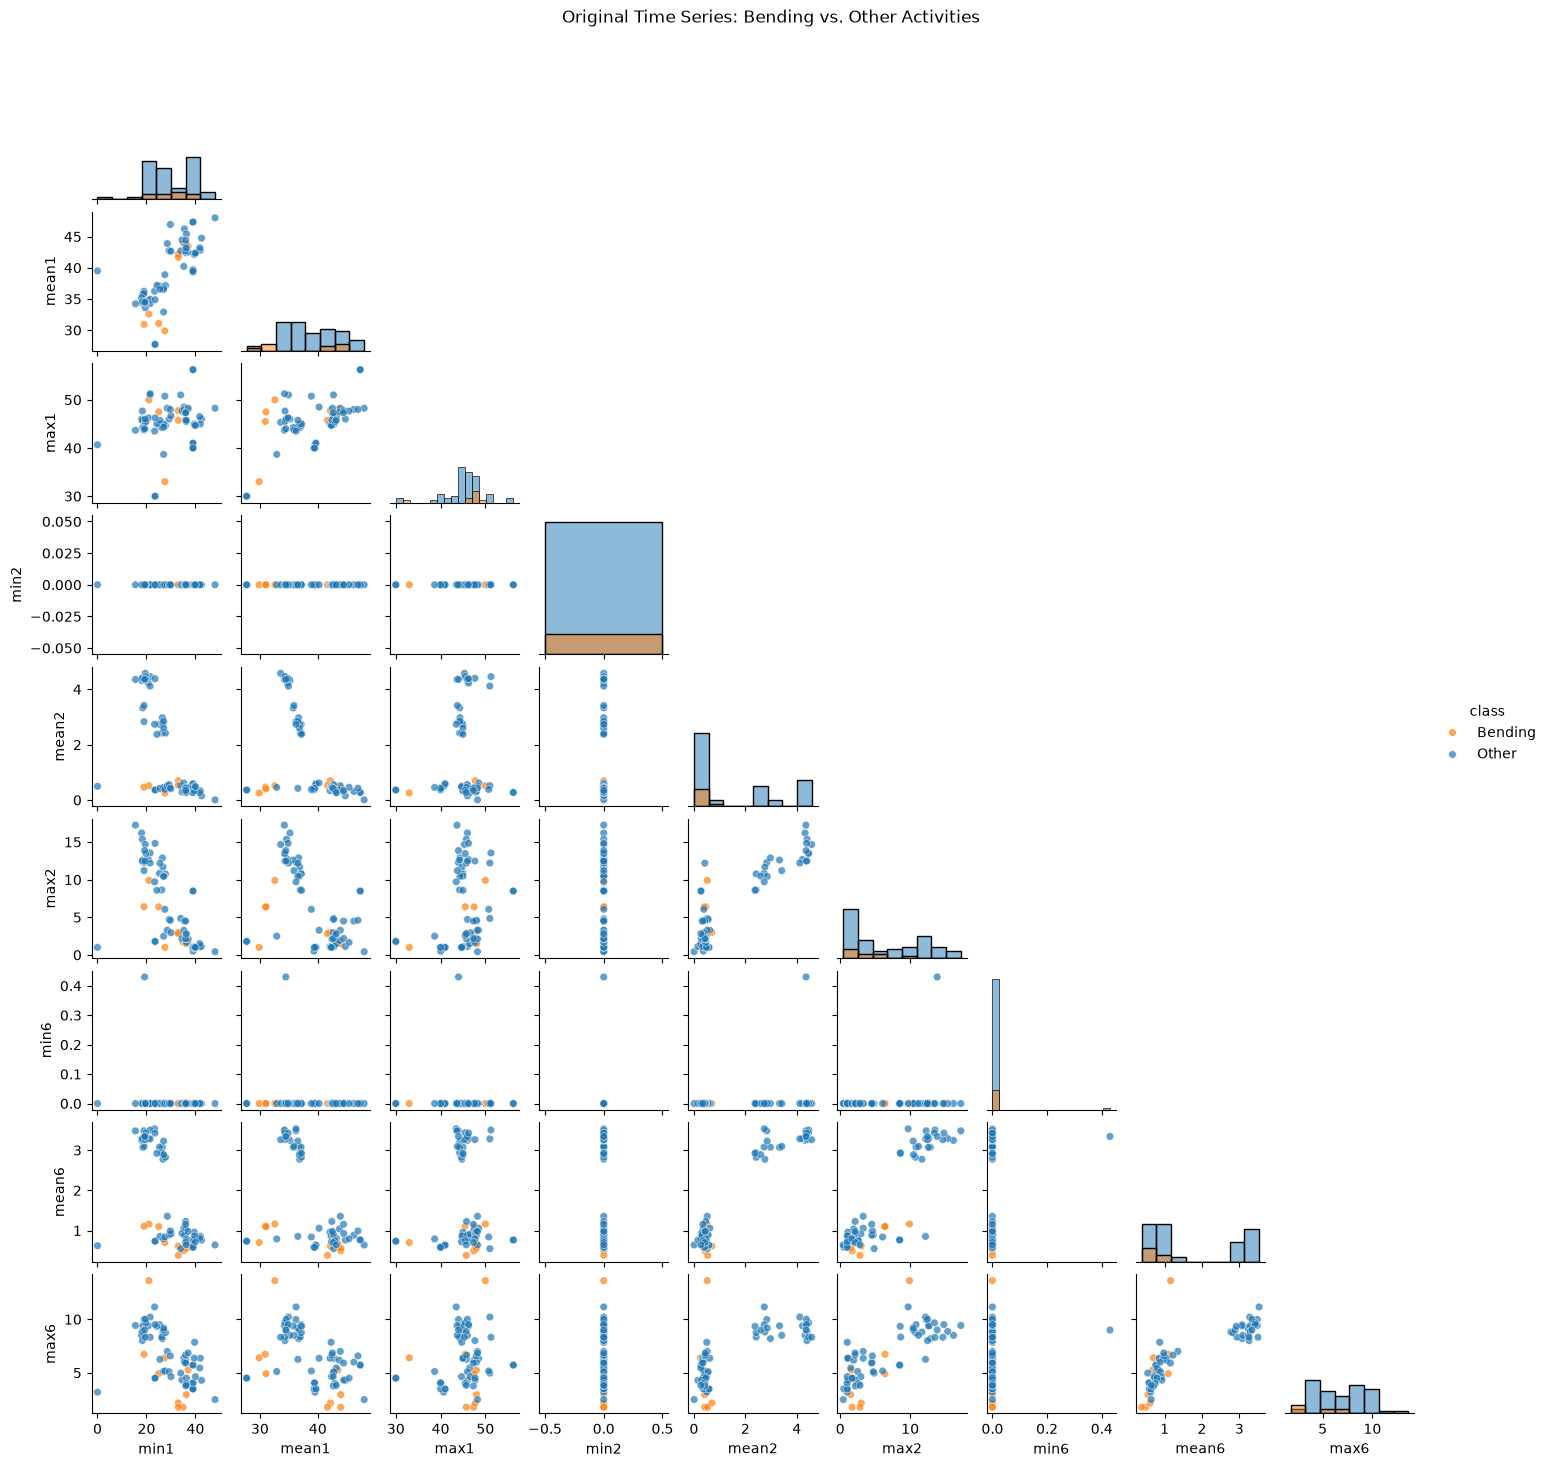

In [13]:
# Extract features from the original training instances.
train_features_original = extract_selected_features(
    train_instances,
    n_parts=1
)

plot_columns_original = [
    f"{feature}{series_number}"
    for series_number in selected_series
    for feature in selected_statistics
]

palette = {
    "Bending": "tab:orange",
    "Other": "tab:blue"
}

g = sns.pairplot(
    data=train_features_original,
    vars=plot_columns_original,
    hue="class",
    hue_order=["Bending", "Other"],
    palette=palette,
    diag_kind="hist",
    corner=True,
    height=1.6,
    plot_kws={"alpha": 0.7, "s": 30}
)

g.fig.suptitle(
    "Original Time Series: Bending vs. Other Activities",
    y=1.02
)

plt.show()

#### ii. Splitted Plots

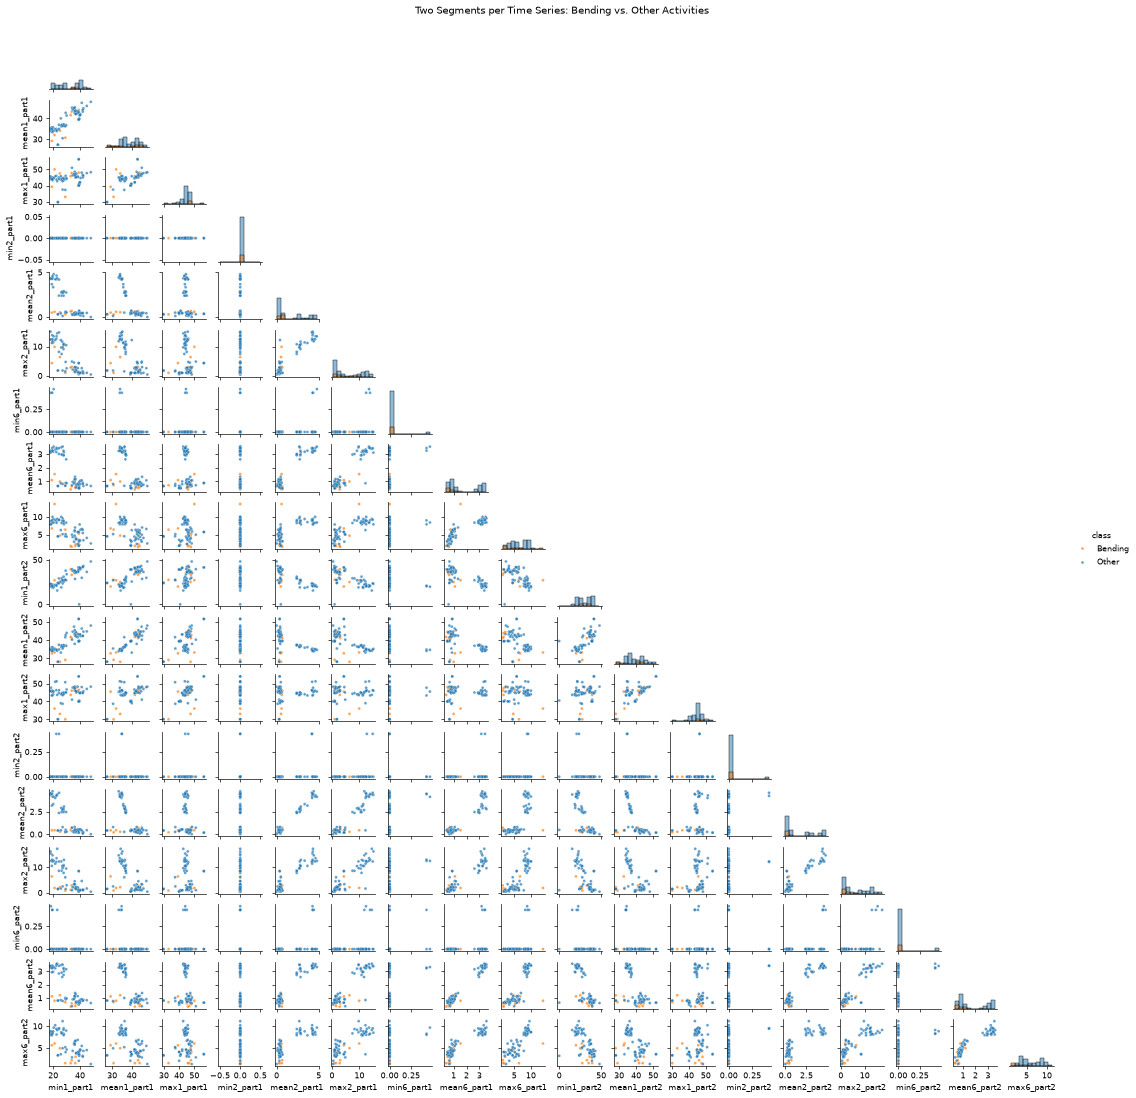

In [14]:
# Close any partially created figures.
plt.close("all")

selected_statistics = ["min", "mean", "max"]
selected_series = [1, 2, 6]

train_features_split = extract_selected_features(
    train_instances,
    n_parts=2
)

plot_columns_split = [
    f"{feature}{series_number}_part{part_number}"
    for part_number in [1, 2]
    for series_number in selected_series
    for feature in selected_statistics
]

# Check column names before creating the large figure.
missing = [
    column for column in plot_columns_split
    if column not in train_features_split.columns
]

if missing:
    raise ValueError(f"Missing feature columns: {missing}")

g = sns.pairplot(
    data=train_features_split,
    vars=plot_columns_split,
    hue="class",
    hue_order=["Bending", "Other"],
    palette=palette,
    diag_kind="hist",
    corner=True,
    height=1.0,
    plot_kws={"alpha": 0.7, "s": 12},
    diag_kws={"bins": 10}
)

g.fig.suptitle(
    "Two Segments per Time Series: Bending vs. Other Activities",
    y=1.02
)

g.fig.set_dpi(60)
plt.show()

**Answer:**
There is no considerable difference in class separation after splitting the time series. Some feature values change, but bending and other activities still overlap in many plots. Therefore, splitting does not appear to substantially improve visual separation.

#### iii. Time Series Segments

##### 1. Define extract egment features function to extract any number of segments

In [15]:
def extract_segment_features(instances, l):
    rows = []

    for instance in instances:
        data = instance["data"]
        row = {}

        # Consecutive, approximately equal-length segments.
        segments = np.array_split(np.arange(len(data)), l)

        for part_number, indices in enumerate(segments, start=1):
            segment = data.iloc[indices]

            for series_number, column in enumerate(
                time_series_columns, start=1
            ):
                values = segment[column]

                statistics = {
                    "min": values.min(),
                    "max": values.max(),
                    "mean": values.mean(),
                    "median": values.median(),
                    "std": values.std(ddof=1),
                    "q1": values.quantile(0.25),
                    "q3": values.quantile(0.75)
                }

                for statistic, value in statistics.items():
                    name = (
                        f"{statistic}{series_number}"
                        f"_part{part_number}"
                    )
                    row[name] = value

        rows.append(row)

    return pd.DataFrame(rows)


# Bending = 1; all other activities = 0.
y_train = np.array([
    int(instance["activity"] in ["bending1", "bending2"])
    for instance in train_instances
])

print("Training instances:", len(y_train))
print("Bending instances:", y_train.sum())
print("Other instances:", (y_train == 0).sum())

Training instances: 69
Bending instances: 9
Other instances: 60


##### 2. Search for the best ($l$, $p$)

In [16]:
# Reuse the same folds for every value of l.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_splits = list(cv.split(np.zeros(len(y_train)), y_train))

results = []
all_cv_results = []
best_model = None
best_X_train = None
best_key = None

for l in range(1, 21):
    X_train_l = extract_segment_features(train_instances, l)

    estimator = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            solver="liblinear",
            C=1.0,
            max_iter=5000,
            random_state=42
        ))
    ])

    selector = RFECV(
        estimator=estimator,
        step=1,
        min_features_to_select=1,
        cv=cv_splits,
        scoring="accuracy",
        importance_getter="named_steps.logistic.coef_",
        n_jobs=-1
    )

    print(
        f"Starting l={l}: {X_train_l.shape[1]} candidate features",
        flush=True
    )

    selector.fit(X_train_l, y_train)

    scores = selector.cv_results_["mean_test_score"]

    # With step=1, scores correspond to p=1, 2, ..., 42*l.
    p_values = np.arange(1, X_train_l.shape[1] + 1)

    all_cv_results.append(pd.DataFrame({
        "l": l,
        "p": p_values,
        "cv_accuracy": scores
    }))

    p = int(selector.n_features_)
    score = float(scores[p - 1])

    results.append({
        "l": l,
        "candidate_features": X_train_l.shape[1],
        "p": p,
        "cv_accuracy": score,
        "cv_error": 1 - score
    })

    # Prefer fewer features, then smaller l, if scores tie.
    key = (score, -p, -l)

    if best_key is None or key > best_key:
        best_key = key
        best_model = selector
        best_X_train = X_train_l
        best_l = l
        best_p = p
        best_cv_accuracy = score

    print(
        f"Finished l={l}: p={p}, CV accuracy={score:.4f}",
        flush=True
    )

results_df = pd.DataFrame(results)
cv_results_df = pd.concat(all_cv_results, ignore_index=True)

display(results_df)

print(f"\nBest (l, p): ({best_l}, {best_p})")
print(f"Mean CV accuracy: {best_cv_accuracy:.4f}")
print(f"Mean CV error: {1 - best_cv_accuracy:.4f}")

best_feature_names = best_X_train.columns[
    best_model.support_
].tolist()

print("\nSelected features:")
print(best_feature_names)

Starting l=1: 42 candidate features
Finished l=1: p=29, CV accuracy=0.9857
Starting l=2: 84 candidate features
Finished l=2: p=12, CV accuracy=0.9714
Starting l=3: 126 candidate features
Finished l=3: p=2, CV accuracy=0.9714
Starting l=4: 168 candidate features
Finished l=4: p=2, CV accuracy=0.9714
Starting l=5: 210 candidate features
Finished l=5: p=11, CV accuracy=0.9714
Starting l=6: 252 candidate features
Finished l=6: p=2, CV accuracy=0.9714
Starting l=7: 294 candidate features
Finished l=7: p=13, CV accuracy=0.9571
Starting l=8: 336 candidate features
Finished l=8: p=1, CV accuracy=0.9429
Starting l=9: 378 candidate features
Finished l=9: p=1, CV accuracy=0.9429
Starting l=10: 420 candidate features
Finished l=10: p=5, CV accuracy=0.9714
Starting l=11: 462 candidate features
Finished l=11: p=2, CV accuracy=0.9714
Starting l=12: 504 candidate features
Finished l=12: p=1, CV accuracy=0.9714
Starting l=13: 546 candidate features
Finished l=13: p=1, CV accuracy=0.9714
Starting l=14: 

,l,candidate_features,p,cv_accuracy,cv_error
0,1,42,29,0.985714,0.014286
1,2,84,12,0.971429,0.028571
2,3,126,2,0.971429,0.028571
3,4,168,2,0.971429,0.028571
4,5,210,11,0.971429,0.028571
5,6,252,2,0.971429,0.028571
6,7,294,13,0.957143,0.042857
7,8,336,1,0.942857,0.057143
8,9,378,1,0.942857,0.057143
9,10,420,5,0.971429,0.028571



Best (l, p): (20, 6)
Mean CV accuracy: 0.9857
Mean CV error: 0.0143

Selected features:
['min5_part3', 'mean5_part3', 'q15_part3', 'q31_part12', 'q14_part15', 'min5_part18']


**Answer:** I used recursive feature elimination with 5-fold stratified cross-validation to select ($l$,$p$). Both ($1$,$29$) and ($20$,$6$) achieved the highest mean validation accuracy of 98.57%. I selected ($20$,$6$) because it uses fewer features. Thus, each original series was divided into 20 segments, and 6 of the 840 candidate features were retained.
Stratification preserved approximately the same class proportions in each fold. Scaling and feature selection were performed within each training fold to avoid leaking validation information. Selecting features before cross-validation would incorrectly allow validation observations to influence the model.

#### iv. Confusion Matrix

In [17]:
print("best_model exists:", "best_model" in globals())
print("best_X_train exists:", "best_X_train" in globals())

best_model exists: True
best_X_train exists: True


Training accuracy: 1.0000
Training AUC: 1.0000


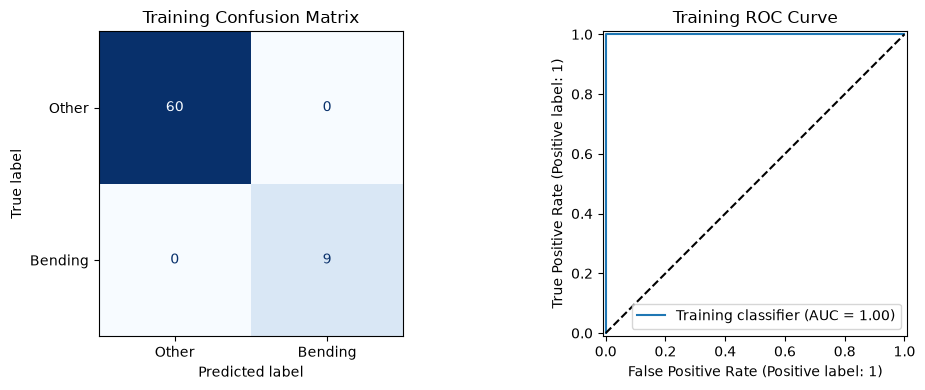

In [18]:
# Predictions from the classifier selected in part iii.
train_predictions = best_model.predict(best_X_train)
train_probabilities = best_model.predict_proba(best_X_train)[:, 1]

train_accuracy = accuracy_score(y_train, train_predictions)
train_auc = roc_auc_score(y_train, train_probabilities)

train_cm = confusion_matrix(
    y_train,
    train_predictions,
    labels=[0, 1]
)

print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Training AUC: {train_auc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    confusion_matrix=train_cm,
    display_labels=["Other", "Bending"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Training Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_train,
    train_probabilities,
    name="Training classifier",
    ax=axes[1]
)

axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("Training ROC Curve")

plt.tight_layout()
plt.show()

In [20]:
# Access the final pipeline fitted by RFECV.
final_pipeline = best_model.estimator_
scaler = final_pipeline.named_steps["scaler"]
logistic = final_pipeline.named_steps["logistic"]

selected_names = best_X_train.columns[
    best_model.support_
].tolist()

# Report coefficients of the actual regularized classifier.
coefficient_table = pd.DataFrame({
    "parameter": ["Intercept"] + selected_names,
    "regularized_beta": np.r_[
        logistic.intercept_[0],
        logistic.coef_[0]
    ]
})

display(coefficient_table)

# Prepare exactly the selected, standardized training features.
X_selected = best_model.transform(best_X_train)
X_scaled = scaler.transform(X_selected)

X_inference = pd.DataFrame(
    X_scaled,
    columns=selected_names
)

X_inference = sm.add_constant(
    X_inference,
    has_constant="add"
)

# Signed margins: positive margins mean correct classification.
design = X_inference.to_numpy()
signed_design = (2 * y_train - 1)[:, None] * design
n_parameters = design.shape[1]

# Complete separation: every signed margin can be >= 1.
complete_check = linprog(
    c=np.zeros(n_parameters),
    A_ub=-signed_design,
    b_ub=-np.ones(len(y_train)),
    bounds=[(None, None)] * n_parameters,
    method="highs"
)

# Quasi-complete separation: all margins >= 0,
# with at least one strictly positive margin.
quasi_check = linprog(
    c=np.zeros(n_parameters),
    A_ub=np.vstack([
        -signed_design,
        -signed_design.sum(axis=0, keepdims=True)
    ]),
    b_ub=np.r_[np.zeros(len(y_train)), -1],
    bounds=[(None, None)] * n_parameters,
    method="highs"
)

if complete_check.success:
    separation_status = "Complete separation"
elif quasi_check.success:
    separation_status = "Quasi-complete separation"
elif complete_check.status == 2 and quasi_check.status == 2:
    separation_status = "No complete or quasi-complete separation detected"
else:
    separation_status = "Separation check inconclusive"

print(separation_status)

if complete_check.success or quasi_check.success:
    print(
        "Finite unpenalized maximum-likelihood estimates are unavailable. "
        "Conventional coefficient p-values are not valid."
    )

else:
    # Separate unpenalized model; does not replace best_model.
    try:
        with warnings.catch_warnings(record=True) as fit_warnings:
            warnings.simplefilter("always")

            inference_fit = sm.Logit(
                y_train,
                X_inference
            ).fit(disp=False, maxiter=1000)

        inference_table = pd.DataFrame({
            "unpenalized_beta": inference_fit.params,
            "standard_error": inference_fit.bse,
            "p_value": inference_fit.pvalues
        })

        display(inference_table)

        print(
            "Converged:",
            inference_fit.mle_retvals.get("converged", False)
        )

        for warning in fit_warnings:
            print("Fit warning:", warning.message)

    except Exception as error:
        print("Unpenalized fit failed:", error)
        print("Reliable p-values could not be obtained.")

,parameter,regularized_beta
0,Intercept,-2.471108
1,min5_part3,0.673505
2,mean5_part3,0.683294
3,q15_part3,0.757955
4,q31_part12,-0.601661
5,q14_part15,-0.604340
6,min5_part18,0.791588


Complete separation
Finite unpenalized maximum-likelihood estimates are unavailable. Conventional coefficient p-values are not valid.


**Answer:** The classifier correctly classified all 69 training instances, achieving 100% training accuracy and an AUC of 1.00. The coefficient estimates are reported above. Complete separation prevents finite unpenalized maximum-likelihood estimates, so conventional p-values cannot be reliably reported.

#### v. Test Classifier

In [21]:
# Use the same feature extraction as for training.
X_test = extract_segment_features(
    test_instances,
    l=best_l
)

# Match the original training feature order.
X_test = X_test.loc[:, best_X_train.columns]

y_test = np.array([
    int(instance["activity"] in ["bending1", "bending2"])
    for instance in test_instances
])

# Predict only: do not refit on test data.
test_predictions = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)

comparison = pd.DataFrame({
    "Evaluation": [
        "Mean 5-fold validation",
        "Test set"
    ],
    "Accuracy": [
        best_cv_accuracy,
        test_accuracy
    ]
})

display(comparison)

difference = 100 * (test_accuracy - best_cv_accuracy)

print(f"Test accuracy: {test_accuracy:.4f}")
print(
    "Test accuracy minus CV accuracy: "
    f"{difference:+.2f} percentage points"
)

,Evaluation,Accuracy
0,Mean 5-fold validation,0.985714
1,Test set,0.947368


Test accuracy: 0.9474
Test accuracy minus CV accuracy: -3.83 percentage points


**Answer:** Test accuracy was 94.74% (18 of 19 instances correct), compared with 98.57% mean cross-validation accuracy. This decrease of 3.83 percentage points suggests slightly lower performance on unseen data, although test accuracy remained high.

#### vi. Separation

**Answer:** Yes. The training classes are completely separated, which makes ordinary logistic regression coefficients unstable and p-values unreliable. Regularization keeps the coefficients finite.

#### vii. Imbalance

**Answer:** Yes, the classes are imbalanced. Even though the training classifer produced no errors, the training set contains 60 other activities but only 9 bending instances, and is therefore considered imbalanced. 

##### 1. Create balanaced sample based on case-control sampling

In [22]:
# Prepare the six selected features using the original scaler.
selected_names = best_X_train.columns[
    best_model.support_
].tolist()

original_scaler = best_model.estimator_.named_steps["scaler"]

X_train_selected = best_X_train[selected_names].to_numpy()
X_test_selected = X_test[selected_names].to_numpy()

X_train_scaled = original_scaler.transform(X_train_selected)
X_test_scaled = original_scaler.transform(X_test_selected)

# Keep every original instance and add sampled bending instances.
rng = np.random.default_rng(42)

other_indices = np.flatnonzero(y_train == 0)
bending_indices = np.flatnonzero(y_train == 1)

extra_bending = rng.choice(
    bending_indices,
    size=len(other_indices) - len(bending_indices),
    replace=True
)

sample_indices = np.concatenate([
    other_indices,
    bending_indices,
    extra_bending
])

rng.shuffle(sample_indices)

X_case_control = X_train_scaled[sample_indices]
y_case_control = y_train[sample_indices]

print("Balanced sample counts:")
print(pd.Series(y_case_control).value_counts().sort_index())

case_control_model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=5000,
    random_state=42
)

case_control_model.fit(X_case_control, y_case_control)

# Adjust the intercept for the original training class proportions.
original_prior = y_train.mean()
sample_prior = y_case_control.mean()

correction = (
    np.log(original_prior / (1 - original_prior))
    - np.log(sample_prior / (1 - sample_prior))
)

sample_intercept = case_control_model.intercept_[0]
case_control_model.intercept_[0] += correction

print(f"\nSample intercept: {sample_intercept:.4f}")
print(f"Intercept correction: {correction:.4f}")
print(
    f"Adjusted intercept: "
    f"{case_control_model.intercept_[0]:.4f}"
)

Balanced sample counts:
0    60
1    60
Name: count, dtype: int64

Sample intercept: -2.3695
Intercept correction: -1.8971
Adjusted intercept: -4.2666


##### 2. Report confusion matricies and ROC+AUC Curves

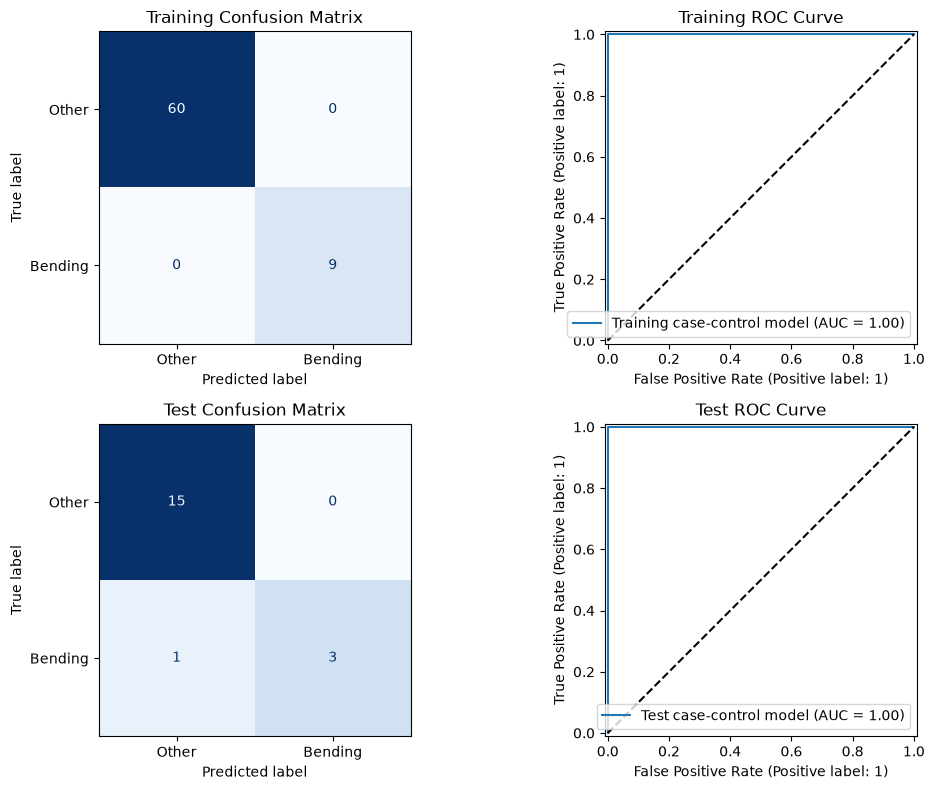

,Dataset,Accuracy,AUC
0,Training,1.000000,1.0
1,Test,0.947368,1.0


In [23]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
evaluation_results = []

datasets = [
    ("Training", X_train_scaled, y_train),
    ("Test", X_test_scaled, y_test)
]

for row, (name, X, y) in enumerate(datasets):
    predictions = case_control_model.predict(X)
    probabilities = case_control_model.predict_proba(X)[:, 1]

    accuracy = accuracy_score(y, predictions)
    auc = roc_auc_score(y, probabilities)

    evaluation_results.append({
        "Dataset": name,
        "Accuracy": accuracy,
        "AUC": auc
    })

    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(
            y, predictions, labels=[0, 1]
        ),
        display_labels=["Other", "Bending"]
    ).plot(
        ax=axes[row, 0],
        cmap="Blues",
        colorbar=False
    )

    axes[row, 0].set_title(f"{name} Confusion Matrix")

    RocCurveDisplay.from_predictions(
        y,
        probabilities,
        name=f"{name} case-control model",
        ax=axes[row, 1]
    )

    axes[row, 1].plot([0, 1], [0, 1], "k--")
    axes[row, 1].set_title(f"{name} ROC Curve")

plt.tight_layout()
plt.show()

display(pd.DataFrame(evaluation_results))

**Answer:** I oversampled bending to create a balanced training sample of 60 instances per class and adjusted the intercept from −2.3695 to −4.2666. The model achieved 100% training accuracy and 94.74% test accuracy, with AUC = 1.00 on both sets. One test bending instance was misclassified as another activity, so test accuracy did not improve over the original model.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [30]:
l1_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

l1_splits = list(
    l1_cv.split(np.zeros(len(y_train)), y_train)
)

C_values = np.logspace(-4, 4, 17)

l1_results = []
l1_best_key = None

for l in range(1, 21):
    X_l = extract_segment_features(train_instances, l)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            l1_ratio=1,
            solver="liblinear",
            max_iter=20000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"logistic__C": C_values},
        scoring="accuracy",
        cv=l1_splits,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    print(f"Starting l={l}", flush=True)
    search.fit(X_l, y_train)

    fitted_model = search.best_estimator_
    C = float(search.best_params_["logistic__C"])
    score = float(search.best_score_)

    coefficients = fitted_model.named_steps["logistic"].coef_[0]
    n_selected = int(np.count_nonzero(coefficients))

    l1_results.append({
        "l": l,
        "C": C,
        "selected_features": n_selected,
        "cv_accuracy": score,
        "cv_error": 1 - score
    })

    # If scores tie, prefer stronger regularization,
    # then fewer segments.
    key = (score, -C, -l)

    if l1_best_key is None or key > l1_best_key:
        l1_best_key = key
        l1_best_model = fitted_model
        l1_best_l = l
        l1_best_C = C
        l1_best_cv_accuracy = score
        l1_best_columns = X_l.columns.tolist()

    print(
        f"Finished l={l}: C={C:.4g}, "
        f"selected={n_selected}, CV accuracy={score:.4f}",
        flush=True
    )

l1_results_df = pd.DataFrame(l1_results)
display(l1_results_df)

print(f"\nBest l: {l1_best_l}")
print(f"Best C: {l1_best_C:.4g}")
print(f"Best CV accuracy: {l1_best_cv_accuracy:.4f}")

Starting l=1
Finished l=1: C=1e+04, selected=36, CV accuracy=0.9714
Starting l=2
Finished l=2: C=1, selected=8, CV accuracy=0.9571
Starting l=3
Finished l=3: C=0.3162, selected=5, CV accuracy=0.9714
Starting l=4
Finished l=4: C=1, selected=10, CV accuracy=0.9571
Starting l=5
Finished l=5: C=3.162, selected=14, CV accuracy=0.9418
Starting l=6
Finished l=6: C=3.162, selected=17, CV accuracy=0.9571
Starting l=7
Finished l=7: C=0.3162, selected=7, CV accuracy=0.9275
Starting l=8
Finished l=8: C=1000, selected=72, CV accuracy=0.9429
Starting l=9
Finished l=9: C=3162, selected=133, CV accuracy=0.9286
Starting l=10
Finished l=10: C=100, selected=30, CV accuracy=0.9714
Starting l=11
Finished l=11: C=1, selected=8, CV accuracy=0.9714
Starting l=12
Finished l=12: C=1, selected=7, CV accuracy=0.9714
Starting l=13
Finished l=13: C=0.3162, selected=6, CV accuracy=0.9714
Starting l=14
Finished l=14: C=1, selected=12, CV accuracy=0.9714
Starting l=15
Finished l=15: C=100, selected=41, CV accuracy=0.9

,l,C,selected_features,cv_accuracy,cv_error
0,1,10000.000000,36,0.971429,0.028571
1,2,1.000000,8,0.957143,0.042857
2,3,0.316228,5,0.971429,0.028571
3,4,1.000000,10,0.957143,0.042857
4,5,3.162278,14,0.941758,0.058242
5,6,3.162278,17,0.957143,0.042857
6,7,0.316228,7,0.927473,0.072527
7,8,1000.000000,72,0.942857,0.057143
8,9,3162.277660,133,0.928571,0.071429
9,10,100.000000,30,0.971429,0.028571



Best l: 19
Best C: 1
Best CV accuracy: 0.9857


In [31]:
l1_coefficients = (
    l1_best_model.named_steps["logistic"].coef_[0]
)

l1_coefficient_table = pd.DataFrame({
    "feature": l1_best_columns,
    "coefficient": l1_coefficients
})

l1_selected_features = l1_coefficient_table.loc[
    l1_coefficient_table["coefficient"] != 0
].reset_index(drop=True)

print("Number of selected features:", len(l1_selected_features))
display(l1_selected_features)

Number of selected features: 10


,feature,coefficient
0,min5_part2,0.054352
1,min5_part3,0.035704
2,q15_part3,2.125566
3,max5_part5,0.011234
4,max1_part11,-0.572018
5,std4_part14,-0.051915
6,std6_part15,-0.215903
7,min5_part17,0.619964
8,std5_part18,-0.075329
9,max6_part18,-0.119019


#### ii. Comparison

In [32]:
# Evaluate the selected L1 model.
X_test_l1 = extract_segment_features(
    test_instances,
    l=l1_best_l
).loc[:, l1_best_columns]

l1_test_predictions = l1_best_model.predict(X_test_l1)

l1_test_accuracy = accuracy_score(
    y_test,
    l1_test_predictions
)

# Evaluate the earlier RFE classifier for comparison.
X_test_rfe = extract_segment_features(
    test_instances,
    l=best_l
).loc[:, best_X_train.columns]

rfe_test_accuracy = accuracy_score(
    y_test,
    best_model.predict(X_test_rfe)
)

comparison_df = pd.DataFrame({
    "Method": ["RFE + L2 logistic regression", "L1 logistic regression"],
    "Best l": [best_l, l1_best_l],
    "Selected features": [
        len(best_feature_names),
        len(l1_selected_features)
    ],
    "CV accuracy": [
        best_cv_accuracy,
        l1_best_cv_accuracy
    ],
    "Test accuracy": [
        rfe_test_accuracy,
        l1_test_accuracy
    ]
})

display(comparison_df)

,Method,Best l,Selected features,CV accuracy,Test accuracy
0,RFE + L2 logistic regression,20,6,0.985714,0.947368
1,L1 logistic regression,19,10,0.985714,0.947368


**Answer:** 
Both methods achieved the same cross-validation accuracy of 98.57% and test accuracy of 94.74%, so neither performed better. RFE retained 6 features, while L1 retained 10. L1 was easier to implement because it selected features during model fitting and avoided unreliable p-values caused by complete separation.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [37]:
def find_best_multiclass_model(name, pipeline, parameter_grid):
    best_result = None
    search_rows = []

    for l in range(1, 21):
        X_l = extract_segment_features(train_instances, l)

        print(f"Starting {name}, l={l}", flush=True)

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=parameter_grid,
            scoring="accuracy",
            cv=multi_splits,
            n_jobs=-1,
            refit=True,
            error_score="raise"
        )

        search.fit(X_l, y_train_multi)

        score = float(search.best_score_)

        search_rows.append({
            "l": l,
            "CV accuracy": score,
            "Parameters": search.best_params_
        })

        # Prefer fewer segments when scores tie.
        key = (score, -l)

        if best_result is None or key > best_result["key"]:
            best_result = {
                "key": key,
                "l": l,
                "model": search.best_estimator_,
                "columns": X_l.columns.tolist(),
                "cv_accuracy": score,
                "parameters": search.best_params_
            }

        print(
            f"Finished: CV accuracy={score:.4f}, "
            f"parameters={search.best_params_}",
            flush=True
        )

    display(pd.DataFrame(search_rows))

    print(f"\nBest l: {best_result['l']}")
    print("Best parameters:", best_result["parameters"])
    print(f"Best CV accuracy: {best_result['cv_accuracy']:.4f}")

    return best_result

def evaluate_multiclass_model(name, result):
    X_test_model = extract_segment_features(
        test_instances,
        l=result["l"]
    ).loc[:, result["columns"]]

    model = result["model"]

    predictions = model.predict(X_test_model)
    probabilities = model.predict_proba(X_test_model)

    accuracy = accuracy_score(y_test_multi, predictions)

    macro_auc = roc_auc_score(
        y_test_multi,
        probabilities,
        labels=class_ids,
        multi_class="ovr",
        average="macro"
    )

    print(f"Test accuracy: {accuracy:.4f}")
    print(f"Test error: {1 - accuracy:.4f}")
    print(f"Macro one-vs-rest AUC: {macro_auc:.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(
            y_test_multi,
            predictions,
            labels=class_ids
        ),
        display_labels=class_names
    ).plot(
        ax=axes[0],
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45
    )

    axes[0].set_title(f"{name}: Test Confusion Matrix")

    for class_id, class_name in enumerate(class_names):
        binary_labels = (y_test_multi == class_id).astype(int)

        fpr, tpr, _ = roc_curve(
            binary_labels,
            probabilities[:, class_id]
        )

        axes[1].plot(
            fpr,
            tpr,
            label=f"{class_name}: AUC={auc(fpr, tpr):.2f}"
        )

    axes[1].plot([0, 1], [0, 1], "k--")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title(f"{name}: Test One-vs-Rest ROC")
    axes[1].legend(loc="lower right", fontsize=8)

    plt.tight_layout()
    plt.show()

    return {
        "Method": name,
        "Best l": result["l"],
        "CV accuracy": result["cv_accuracy"],
        "Test accuracy": accuracy,
        "Test error": 1 - accuracy,
        "Macro OvR AUC": macro_auc
    }


Starting L1 multinomial logistic, l=1
Finished: CV accuracy=0.8701, parameters={'model__C': np.float64(1.0)}
Starting L1 multinomial logistic, l=2
Finished: CV accuracy=0.9273, parameters={'model__C': np.float64(316.22776601683796)}
Starting L1 multinomial logistic, l=3
Finished: CV accuracy=0.8987, parameters={'model__C': np.float64(1000.0)}
Starting L1 multinomial logistic, l=4
Finished: CV accuracy=0.8840, parameters={'model__C': np.float64(316.22776601683796)}
Starting L1 multinomial logistic, l=5
Finished: CV accuracy=0.9134, parameters={'model__C': np.float64(1000.0)}
Starting L1 multinomial logistic, l=6
Finished: CV accuracy=0.9134, parameters={'model__C': np.float64(3162.2776601683795)}
Starting L1 multinomial logistic, l=7
Finished: CV accuracy=0.8840, parameters={'model__C': np.float64(1000.0)}
Starting L1 multinomial logistic, l=8
Finished: CV accuracy=0.8407, parameters={'model__C': np.float64(316.22776601683796)}
Starting L1 multinomial logistic, l=9
Finished: CV accuracy

,l,CV accuracy,Parameters
0,1,0.870098,{'model__C': 1.0}
1,2,0.927288,{'model__C': 316.22776601683796}
2,3,0.898693,{'model__C': 1000.0}
3,4,0.883987,{'model__C': 316.22776601683796}
4,5,0.913399,{'model__C': 1000.0}
5,6,0.913399,{'model__C': 3162.2776601683795}
6,7,0.883987,{'model__C': 1000.0}
7,8,0.840686,{'model__C': 316.22776601683796}
8,9,0.883987,{'model__C': 3.1622776601683795}
9,10,0.825980,{'model__C': 1000.0}



Best l: 2
Best parameters: {'model__C': np.float64(316.22776601683796)}
Best CV accuracy: 0.9273
Test accuracy: 0.8421
Test error: 0.1579
Macro one-vs-rest AUC: 0.9557


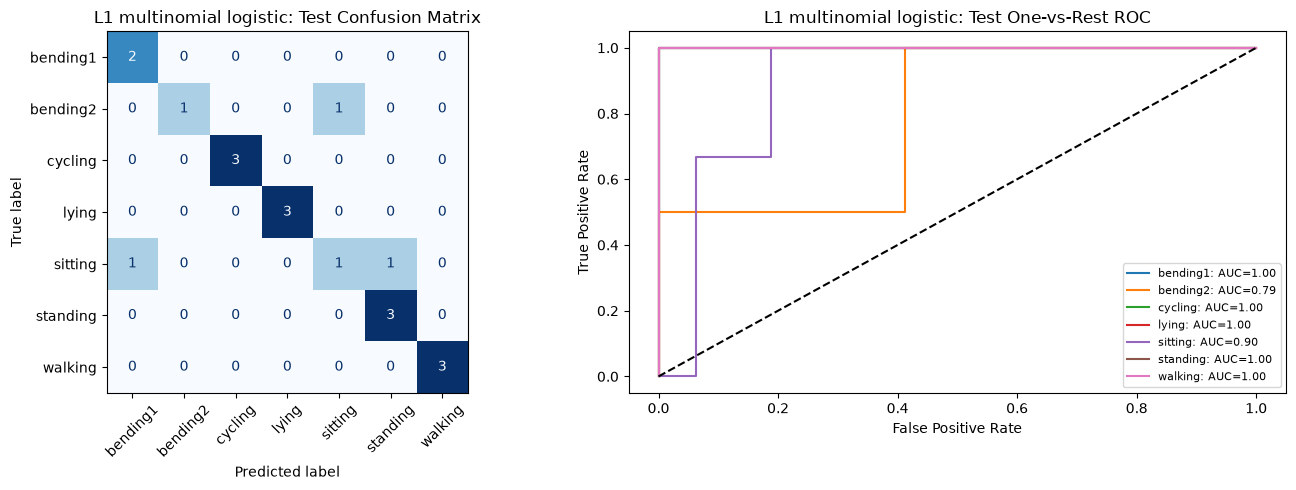

In [38]:
multinomial_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        l1_ratio=1,
        solver="saga",
        max_iter=20000,
        random_state=42
    ))
])

multinomial_best = find_best_multiclass_model(
    name="L1 multinomial logistic",
    pipeline=multinomial_pipeline,
    parameter_grid={
        "model__C": np.logspace(-4, 4, 17)
    }
)

multinomial_metrics = evaluate_multiclass_model(
    "L1 multinomial logistic",
    multinomial_best
)

**Answer:**

For seven activity classes, the confusion matrix is a $7$ x $7$ table. Rows represent actual activities and columns represent predicted activities. Diagonal entries show correct predictions, while off-diagonal entries show misclassifications.

Multiclass ROC curves can be constructed using one-versus-rest: each activity is treated as the positive class and all other activities as negative. Each curve plots the true positive rate against the false positive rate across probability thresholds. I plotted one ROC curve per activity and calculated the macro AUC as the equally weighted average of their AUC values.

References: Scikit-learn: [Confusion Matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html) | [Multiclass ROC](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html)

#### ii. Naive Bayes

##### 1. Gaussian Naive Bayes

Starting Gaussian NB, l=1
Finished: CV accuracy=0.8415, parameters={'model__var_smoothing': np.float64(1e-11)}
Starting Gaussian NB, l=2
Finished: CV accuracy=0.8260, parameters={'model__var_smoothing': np.float64(1e-11)}
Starting Gaussian NB, l=3
Finished: CV accuracy=0.6977, parameters={'model__var_smoothing': np.float64(1e-07)}
Starting Gaussian NB, l=4
Finished: CV accuracy=0.6953, parameters={'model__var_smoothing': np.float64(1e-11)}
Starting Gaussian NB, l=5
Finished: CV accuracy=0.6520, parameters={'model__var_smoothing': np.float64(1e-10)}
Starting Gaussian NB, l=6
Finished: CV accuracy=0.6814, parameters={'model__var_smoothing': np.float64(1e-11)}
Starting Gaussian NB, l=7
Finished: CV accuracy=0.6242, parameters={'model__var_smoothing': np.float64(1e-11)}
Starting Gaussian NB, l=8
Finished: CV accuracy=0.6520, parameters={'model__var_smoothing': np.float64(1e-11)}
Starting Gaussian NB, l=9
Finished: CV accuracy=0.5662, parameters={'model__var_smoothing': np.float64(1e-11)}
S

,l,CV accuracy,Parameters
0,1,0.841503,{'model__var_smoothing': 1e-11}
1,2,0.825980,{'model__var_smoothing': 1e-11}
2,3,0.697712,{'model__var_smoothing': 1e-07}
3,4,0.695261,{'model__var_smoothing': 1e-11}
4,5,0.651961,{'model__var_smoothing': 1e-10}
5,6,0.681373,{'model__var_smoothing': 1e-11}
6,7,0.624183,{'model__var_smoothing': 1e-11}
7,8,0.651961,{'model__var_smoothing': 1e-11}
8,9,0.566176,{'model__var_smoothing': 1e-11}
9,10,0.637255,{'model__var_smoothing': 1e-09}



Best l: 1
Best parameters: {'model__var_smoothing': np.float64(1e-11)}
Best CV accuracy: 0.8415
Test accuracy: 0.8947
Test error: 0.1053
Macro one-vs-rest AUC: 0.9643


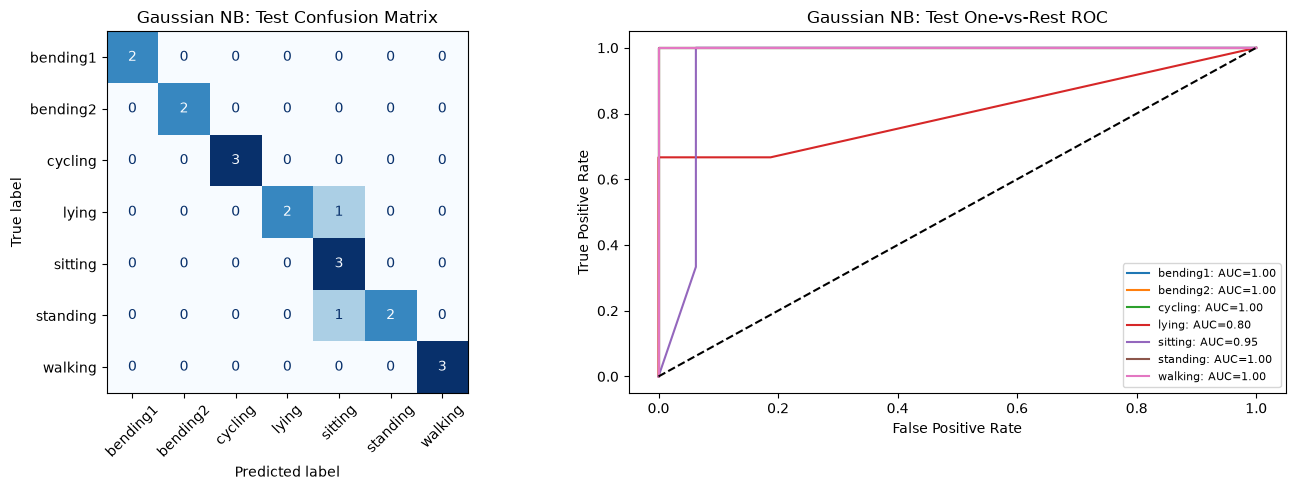

In [39]:
gaussian_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", GaussianNB())
])

gaussian_best = find_best_multiclass_model(
    name="Gaussian NB",
    pipeline=gaussian_pipeline,
    parameter_grid={
        "model__var_smoothing": np.logspace(-11, -7, 5)
    }
)

gaussian_metrics = evaluate_multiclass_model(
    "Gaussian NB",
    gaussian_best
)

##### 2. Multinomial Naive Bayes

Starting Multinomial NB, l=1
Finished: CV accuracy=0.8562, parameters={'model__alpha': 0.01}
Starting Multinomial NB, l=2
Finished: CV accuracy=0.8284, parameters={'model__alpha': 0.1}
Starting Multinomial NB, l=3
Finished: CV accuracy=0.7549, parameters={'model__alpha': 1.0}
Starting Multinomial NB, l=4
Finished: CV accuracy=0.7696, parameters={'model__alpha': 0.01}
Starting Multinomial NB, l=5
Finished: CV accuracy=0.7974, parameters={'model__alpha': 0.01}
Starting Multinomial NB, l=6
Finished: CV accuracy=0.7843, parameters={'model__alpha': 0.01}
Starting Multinomial NB, l=7
Finished: CV accuracy=0.7974, parameters={'model__alpha': 0.1}
Starting Multinomial NB, l=8
Finished: CV accuracy=0.7974, parameters={'model__alpha': 0.01}
Starting Multinomial NB, l=9
Finished: CV accuracy=0.7843, parameters={'model__alpha': 0.01}
Starting Multinomial NB, l=10
Finished: CV accuracy=0.8554, parameters={'model__alpha': 0.01}
Starting Multinomial NB, l=11
Finished: CV accuracy=0.7974, parameters={

,l,CV accuracy,Parameters
0,1,0.856209,{'model__alpha': 0.01}
1,2,0.828431,{'model__alpha': 0.1}
2,3,0.754902,{'model__alpha': 1.0}
3,4,0.769608,{'model__alpha': 0.01}
4,5,0.797386,{'model__alpha': 0.01}
5,6,0.784314,{'model__alpha': 0.01}
6,7,0.797386,{'model__alpha': 0.1}
7,8,0.797386,{'model__alpha': 0.01}
8,9,0.784314,{'model__alpha': 0.01}
9,10,0.855392,{'model__alpha': 0.01}



Best l: 1
Best parameters: {'model__alpha': 0.01}
Best CV accuracy: 0.8562
Test accuracy: 0.8421
Test error: 0.1579
Macro one-vs-rest AUC: 0.9762


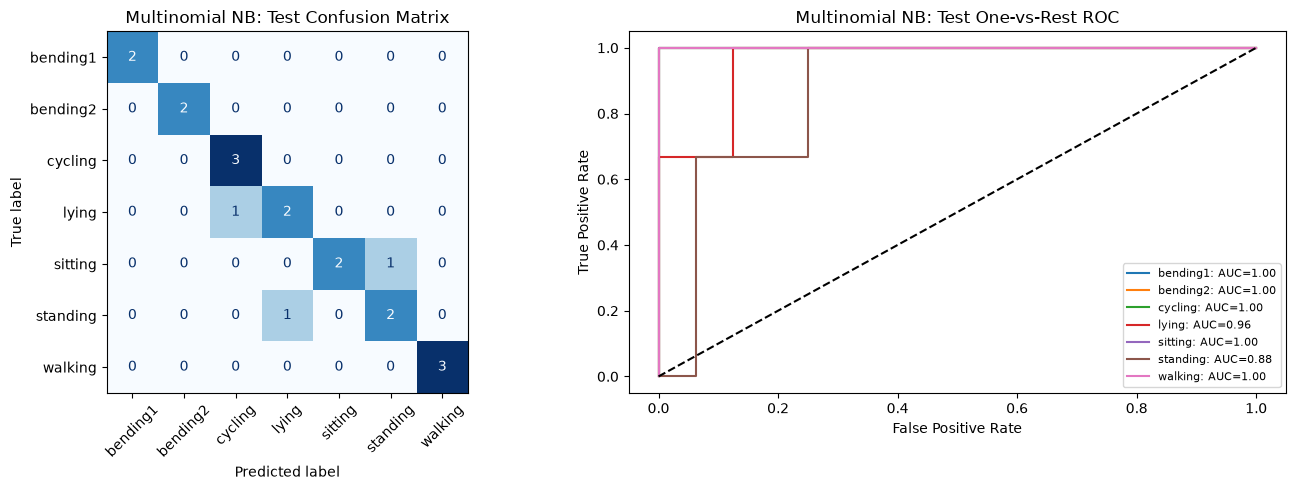

In [40]:
multinomial_nb_pipeline = Pipeline([
    ("scaler", MinMaxScaler(clip=True)),
    ("model", MultinomialNB())
])

multinomial_nb_best = find_best_multiclass_model(
    name="Multinomial NB",
    pipeline=multinomial_nb_pipeline,
    parameter_grid={
        "model__alpha": [0.01, 0.1, 1.0, 10.0]
    }
)

multinomial_nb_metrics = evaluate_multiclass_model(
    "Multinomial NB",
    multinomial_nb_best
)

In [41]:
nb_comparison = pd.DataFrame([
    gaussian_metrics,
    multinomial_nb_metrics
])

display(nb_comparison)

,Method,Best l,CV accuracy,Test accuracy,Test error,Macro OvR AUC
0,Gaussian NB,1,0.841503,0.894737,0.105263,0.964286
1,Multinomial NB,1,0.856209,0.842105,0.157895,0.976190


**Answer:** Gaussian Naive Bayes performed better on the test set, achieving 89.47% accuracy and 10.53% error, compared with Multinomial Naive Bayes’ 84.21% accuracy and 15.79% error. Both selected $l$=1. Although Multinomial NB had slightly higher cross-validation accuracy and macro AUC, Gaussian NB made fewer test classification errors.

#### iii. Comparison

In [42]:
multiclass_comparison = pd.DataFrame([
    multinomial_metrics,
    gaussian_metrics,
    multinomial_nb_metrics
])

display(
    multiclass_comparison.sort_values(
        by="Test error"
    ).reset_index(drop=True)
)

,Method,Best l,CV accuracy,Test accuracy,Test error,Macro OvR AUC
0,Gaussian NB,1,0.841503,0.894737,0.105263,0.964286
1,L1 multinomial logistic,2,0.927288,0.842105,0.157895,0.955707
2,Multinomial NB,1,0.856209,0.842105,0.157895,0.976190


**Answer:** Gaussian Naive Bayes performed best on the test set, with 89.47% accuracy and 10.53% error. L1 multinomial logistic regression and Multinomial Naive Bayes both achieved 84.21% accuracy and 15.79% error. Although L1 logistic regression had the highest cross-validation accuracy, Gaussian NB correctly classified one more test instance.

## 3. ISLR 4.8.3

**Answer:**

The Bayes classifier assigns $x$ to the class with the largest value of $\pi_k f_k(x)$, where $\pi_k$ is the prior probability of class $k$ and $f_k(x)$ is the density for that class.

For a normal distribution,

$$
f_k(x)=\frac{1}{\sqrt{2\pi\sigma_k^2}}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).
$$

Taking the log of $\pi_k f_k(x)$ gives the discriminant for class $k$:

$$
\begin{aligned}
\delta_k(x)
&=\log(\pi_k f_k(x))\\
&=\log\pi_k-\frac{1}{2}\log(2\pi\sigma_k^2)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}\\
&=-\frac{1}{2\sigma_k^2}x^2
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\frac{1}{2}\log(2\pi\sigma_k^2)+\log\pi_k.
\end{aligned}
$$

This expression includes an $x^2$ term, so the discriminant is quadratic in $x$. To find the boundary between two classes, we set their discriminants equal. If their variances are different, the $x^2$ terms generally do not cancel, so the boundary equation is quadratic. It can have two solutions.

Therefore, the Bayes classifier is generally quadratic when the classes have different variances. If all the class variances are equal, the $x^2$ terms cancel and the discriminants become linear, as they do in LDA.

## 4. ISLR 4.8.7

**Answer:**

Let $D$ mean the company issues a dividend. We want to find $P(D \mid X=4)$. By Bayes’ theorem,

$$
P(D\mid X=4)
=
\frac{f(4\mid D)P(D)}
{f(4\mid D)P(D)+f(4\mid D^c)P(D^c)}.
$$

The mean profit was $10$ for companies that issued dividends and $0$ for companies that did not. Both groups have variance $36$, and the prior probabilities are $P(D)=0.8$ and $P(D^c)=0.2$. Using the normal density, the common factor $1/\sqrt{2\pi(36)}$ cancels:

$$
P(D\mid X=4)
=
\frac{0.8e^{-(4-10)^2/(2\cdot36)}}
{0.8e^{-(4-10)^2/(2\cdot36)}
+0.2e^{-(4-0)^2/(2\cdot36)}}.
$$

Therefore,

$$
P(D\mid X=4)
=
\frac{0.8e^{-1/2}}
{0.8e^{-1/2}+0.2e^{-2/9}}
\approx 0.752.
$$

So, the predicted probability that the company will issue a dividend is about **75.2%**.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9